### Load the model

In [ ]:
from model import groq_model

In [ ]:
from langchain.tools import tool
import requests
import os
from dotenv import load_dotenv

load_dotenv()   
base_url = os.getenv('BASE_URL')

@tool
def call_login_api(username:str, password:str):
    """Calls the login API"""

    request_body = {
    "username" : username,
    "password" : password
    }

    response = requests.post(base_url + "login",json = request_body)

    return {
        "status" : response.status_code,
        "message" : response.json()
    }


In [4]:
from typing import Annotated,TypedDict
import operator
from langchain.messages import AnyMessage

class State(TypedDict):
    messages : Annotated[list[AnyMessage],operator.add]
    status:int

In [ ]:
tools = [call_login_api]
model_with_tool = groq_model.bind_tools(tools)

In [6]:
from typing import Dict
from langchain.messages import SystemMessage

def llm_call(state: Dict):
    """Call the LLM Model"""

    response = model_with_tool.invoke(
        [
            SystemMessage(content="")
        ]
        + state["messages"]
    )

    return {
        "messages" : [response],
        "status_code" : response.content
    }

In [7]:
from langchain.messages import ToolMessage

def tool_node(state:Dict):
    """Call the tool"""

    messages = state['messages']
    last_message = messages[-1]
    result = []

    for tool_call in last_message.tool_calls:
        id = tool_call['id']
        args = tool_call['args']
        observation = call_login_api.invoke(args)
        result.append(ToolMessage(tool_call_id = id,content = observation))
    return {"messages": result}

In [8]:
from typing import Literal
from langgraph.graph import StateGraph, START, END


def should_continue(state:State) -> Literal["tooL_node",END]:
    """Decide whether to continue or stop"""

    message = state["messages"]
    last_message = message[-1]

    if last_message.tool_calls:
        return "tool_node"

    return END

In [9]:
agent_builder = StateGraph(State)

agent_builder.add_node("llm_call",llm_call)
agent_builder.add_node("tool_node",tool_node)

agent_builder.add_edge(START,"llm_call")
agent_builder.add_conditional_edges(
    "llm_call",
    should_continue,
    ["tool_node",END]
)

agent_builder.add_edge("tool_node","llm_call")

agent = agent_builder.compile()

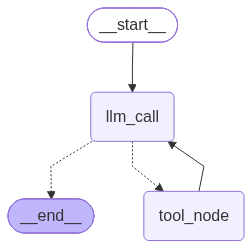

In [10]:
from IPython.display  import Image, display

display(Image(agent.get_graph(xray = True).draw_mermaid_png()))

In [11]:
from langchain.messages import HumanMessage

haha = HumanMessage(content = "Use the tool, call the API using this credentials. Sahil and password is 123232w3")
response = agent.invoke({"messages": [haha]})
print(response)

{'messages': [HumanMessage(content='Use the tool, call the API using this credentials. Sahil and password is 123232w3', additional_kwargs={}, response_metadata={}), AIMessage(content='', additional_kwargs={'reasoning_content': 'The user wants to call the login API with username "Sahil" and password "123232w3". We have a tool call_login_api. We need to call it with those credentials. Then we should respond with the result.', 'tool_calls': [{'id': 'fc_b7cf75d6-5595-401c-b515-aded9961ef12', 'function': {'arguments': '{"password":"123232w3","username":"Sahil"}', 'name': 'call_login_api'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 87, 'prompt_tokens': 144, 'total_tokens': 231, 'completion_time': 0.184354104, 'completion_tokens_details': {'reasoning_tokens': 48}, 'prompt_time': 0.005994481, 'prompt_tokens_details': None, 'queue_time': 0.167101066, 'total_time': 0.190348585}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_df9620fe21', 'serv

define to tool -> state -> node (2) -> edge -> we call the Model